# 05 · Evaluation

How good is the released ensemble, where is it weak, and how much do the ensembling, the TTA option and the clinical
image contribute? Everything is computed from out-of-fold (OOF) predictions: each lesion is scored by the three
seed models that did not see it in training. The score is `0.7·pAUC80 + 0.3·MacroAUC₁₁ − 0.1·FairGap` (README,
"The metric"). We report the **pooled** OOF score, never a mean of fold or seed scores.

_This model was developed for a research competition and is not a medical device._

In [1]:
# Setup: every path comes from configs/final.yaml (milk10k.config); nothing here downloads data.
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RELEASE = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(RELEASE / "src") not in sys.path:
    sys.path.insert(0, str(RELEASE / "src"))  # works without `pip install -e .`
from milk10k.config import load_config
from milk10k.evaluation import (CODE_GROUPS, COMPONENTS, bootstrap_mean_difference, ci95, evaluate, group_counts,
                                load_oof, load_solution, paired_bootstrap, tail_threshold, truth_arrays)
from milk10k.metrics import CLASSES

cfg = load_config()
DATA = cfg["paths"]["data_dir"]  # prepared MILK10k (data/README.md); override with MILK10K_DATA_DIR

# "data:<file>" = under DATA; anything else is relative to the release root.
INPUTS = {
    "train_meta": "data:train_metadata.csv",
    "folds": "data/folds.csv",
    "oof_final": "results/oof/final-P1a-kg_oof.csv",
    "oof_tta": "results/oof/final-P1a-kg-tta_oof.csv",
    "oof_s42": "results/oof/P1a-kg-s42_oof.csv",
    "oof_s43": "results/oof/P1a-kg-s43_oof.csv",
    "oof_s44": "results/oof/P1a-kg-s44_oof.csv",
    "oof_s42_noclin": "results/oof/P1a-kg-s42-noclin_oof.csv",
    "oof_s43_noclin": "results/oof/P1a-kg-s43-noclin_oof.csv",
    "oof_s44_noclin": "results/oof/P1a-kg-s44-noclin_oof.csv",
    "pred_final": "results/predictions/final-P1a-kg.csv",
    "pred_tta": "results/predictions/final-P1a-kg-tta.csv"
}
OUTPUTS = {
    "fig_roc": "results/figures/05_roc_pauc80.png",
    "fig_class_auc": "results/figures/05_per_class_auc.png",
    "fig_calibration": "results/figures/05_calibration.png",
    "fig_test_scores": "results/figures/05_test_score_distribution.png",
    "table_runs": "results/tables/05_run_components.csv",
    "table_class_auc": "results/tables/05_per_class_auc.csv",
    "metrics_json": "results/metrics/final_metrics.json"
}


def inp(key):
    v = INPUTS[key]
    return DATA / v[5:] if v.startswith("data:") else RELEASE / v


def out(key):
    p = RELEASE / OUTPUTS[key]
    p.parent.mkdir(parents=True, exist_ok=True)
    return p


def savefig(key):
    plt.tight_layout()
    plt.savefig(out(key), dpi=120)
    plt.show()


missing = [k for k in INPUTS if not inp(k).exists()]
import os  # noqa: E402
print("data dir from:", "MILK10K_DATA_DIR" if os.environ.get("MILK10K_DATA_DIR") else "configs/final.yaml")
print("checkpoints from:", "MILK10K_CHECKPOINT_DIR" if os.environ.get("MILK10K_CHECKPOINT_DIR") else "configs/final.yaml")
print("missing inputs:", missing or "none")

data dir from: MILK10K_DATA_DIR
checkpoints from: configs/final.yaml
missing inputs: none


## 1. All the variants side by side
The final ensemble, its TTA variant, the three single seeds, and the three seeds without the clinical image.

In [2]:
N_BOOT, BOOT_SEED = 1000, 0  # paired lesion resamples, fixed seed
sol = load_solution(DATA, inp("folds"))
t = truth_arrays(sol)
runs = {"final-P1a-kg": "oof_final", "final-P1a-kg-tta": "oof_tta",
        **{f"P1a-kg-s{s}": f"oof_s{s}" for s in (42, 43, 44)},
        **{f"P1a-kg-s{s}-noclin": f"oof_s{s}_noclin" for s in (42, 43, 44)}}
res = {r: evaluate(t, sol, load_oof(inp(k), sol)) for r, k in runs.items()}


def row(r):
    e = res[r]
    return {"run": r, **{k: e[k] for k in COMPONENTS}, "fold_mean": float(np.mean(e["fold_scores"])),
            "fold_std": float(np.std(e["fold_scores"])), **{CODE_GROUPS[g]: v for g, v in e["pauc80_by_group"].items()}}


table = pd.DataFrame([row(r) for r in runs]).set_index("run")
table.to_csv(out("table_runs"))
table.round(4)

,score,pauc80_norm,macro_auc_11,fair_gap,fold_mean,fold_std,codes 1-2,codes 3-4,codes 5-6
run,,,,,,,,,
final-P1a-kg,0.6505,0.5716,0.8911,0.1693,0.6576,0.0250,0.7228,0.5535,0.5899
final-P1a-kg-tta,0.6555,0.5772,0.8969,0.1760,0.6627,0.0256,0.7347,0.5587,0.5971
P1a-kg-s42,0.6446,0.5565,0.8818,0.0947,0.6457,0.0243,0.6355,0.5409,0.5735
P1a-kg-s43,0.6204,0.5380,0.8775,0.1951,0.6217,0.0310,0.7109,0.5158,0.5679
P1a-kg-s44,0.6237,0.5240,0.8770,0.0626,0.6239,0.0213,0.4560,0.5168,0.5186
P1a-kg-s42-noclin,0.6331,0.5466,0.8771,0.1272,0.6390,0.0278,0.6583,0.5311,0.5619
P1a-kg-s43-noclin,0.6054,0.5129,0.8677,0.1393,0.6103,0.0295,0.6348,0.4956,0.5332
P1a-kg-s44-noclin,0.6161,0.5157,0.8711,0.0625,0.6170,0.0144,0.4463,0.5088,0.5076


## 2. The headline number
Does the released OOF file reproduce the score it had when it was produced (0.6505137677887615)? The assertion fails if not.

In [3]:
REPORTED = 0.6505137677887615  # score of the released OOF predictions when they were produced
final = res["final-P1a-kg"]
assert abs(final["score"] - REPORTED) < 1e-12, final["score"]
print({k: round(final[k], 4) for k in COMPONENTS})
print("fold scores:", [round(x, 4) for x in final["fold_scores"]],
      f"mean {np.mean(final['fold_scores']):.4f} ± {np.std(final['fold_scores']):.4f} (ddof=0)")

{'score': 0.6505, 'pauc80_norm': 0.5716, 'macro_auc_11': 0.8911, 'fair_gap': 0.1693}
fold scores: [0.658, 0.6683, 0.6815, 0.6098, 0.6703] mean 0.6576 ± 0.0250 (ddof=0)


It does, to all printed digits. pAUC80 (0.5716) is clearly the weakest component; macro-AUC is 0.8911. Fold scores range
from 0.610 to 0.681, a reminder of how much a single fold can move.

## 3. Skin-tone groups
How does pAUC80 differ between the code groups behind FairGap? The groups are named by numeric code because the direction
of the source coding is unverified. A group counts only with at least 10 malignant and 10 benign lesions.

In [4]:
gc = group_counts(t)
gc["pauc80_final"] = gc.index.map({CODE_GROUPS[g]: v for g, v in final["pauc80_by_group"].items()})
gc["pauc80_final_tta"] = gc.index.map({CODE_GROUPS[g]: v for g, v in res["final-P1a-kg-tta"]["pauc80_by_group"].items()})
gc

,lesions,malignant,benign,eligible,pauc80_final,pauc80_final_tta
group,,,,,,
codes 1-2,111,38,73,True,0.722783,0.734679
codes 3-4,3680,2431,1249,True,0.553510,0.558664
codes 5-6,1449,985,464,True,0.589926,0.597147


All three groups are eligible, and the small code 1–2 group (111 lesions) scores *highest*: 0.723 vs 0.554 and 0.590.
FairGap (0.169) is therefore driven by the smallest, noisiest group. It is not evidence that the larger groups are poorly served.

## 4. Where on the ROC curve does pAUC80 look?
The shaded band is the region pAUC80 integrates: true-positive rate ≥ 0.8.

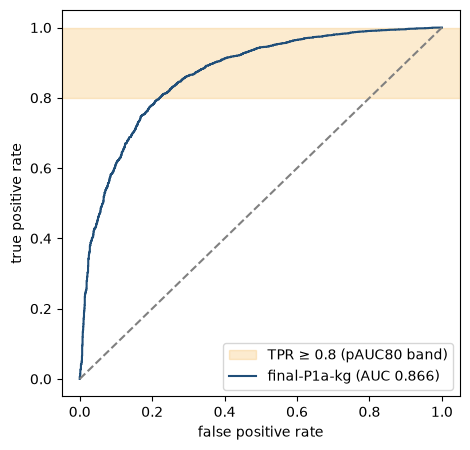

In [5]:
from sklearn.metrics import roc_auc_score, roc_curve

y = t["y_bin"]
p = final["preds"][0]
fpr, tpr, _ = roc_curve(y, p)
fig, ax = plt.subplots(figsize=(4.8, 4.6))
ax.axhspan(0.8, 1.0, color="#f5b041", alpha=0.25, label="TPR ≥ 0.8 (pAUC80 band)")
ax.plot(fpr, tpr, color="#1f4e79", label=f"final-P1a-kg (AUC {roc_auc_score(y, p):.3f})")
ax.plot([0, 1], [0, 1], "--", color="grey")
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate")
ax.legend(loc="lower right")
savefig("fig_roc")

## 5. Which diagnoses are hardest to separate?

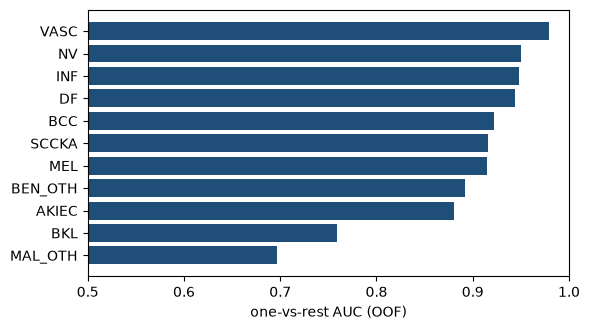

,class,positives,ovr_auc
6,MAL_OTH,9,0.696489
3,BKL,544,0.759050
0,AKIEC,303,0.880698
2,BEN_OTH,44,0.891717
7,MEL,450,0.914333
9,SCCKA,473,0.915925
1,BCC,2522,0.922178
4,DF,52,0.943805
5,INF,50,0.948420
8,NV,746,0.950048


In [6]:
pc = final["preds"][1]
cls_auc = pd.DataFrame([{"class": c, "positives": int((t["y_cls"] == c).sum()),
                         "ovr_auc": roc_auc_score(t["y_cls"] == c, pc[:, i])} for i, c in enumerate(CLASSES)])
cls_auc = cls_auc.sort_values("ovr_auc")
cls_auc.to_csv(out("table_class_auc"), index=False)
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.barh(cls_auc["class"], cls_auc.ovr_auc, color="#1f4e79")
ax.set_xlim(0.5, 1)
ax.set_xlabel("one-vs-rest AUC (OOF)")
savefig("fig_class_auc")
cls_auc

Most classes reach an AUC of 0.88–0.98. The weak ones are BKL (0.759), the benign class that most often outranks
malignant lesions (notebook 02), and MAL_OTH (0.696), which has only 9 lesions.

## 6. How much does averaging three seeds help?
The final ensemble against the mean of the three single-seed scores, with a paired bootstrap over lesions.

In [7]:
seeds = [f"P1a-kg-s{s}" for s in (42, 43, 44)]
mean_single = float(np.mean([res[s]["score"] for s in seeds]))
d_ens = bootstrap_mean_difference(t, [final["preds"]], [res[s]["preds"] for s in seeds], N_BOOT, BOOT_SEED)
ensembling = {"final": final["score"], "mean_single_seed": mean_single, "delta": final["score"] - mean_single,
              "ci95": ci95(d_ens)["score"]}
ensembling

{'final': 0.6505137677887615,
 'mean_single_seed': 0.6295454568136432,
 'delta': 0.02096831097511831,
 'ci95': (0.012279856330125228, 0.03797000674178575)}

Averaging three seeds adds +0.021 (CI +0.012 to +0.038). That is real but just below our decision gate for three seeds
(0.0215; `docs/experiment_log.md`), so we treat the ensemble as the reference recipe averaged, not as a confirmed
improvement.

## 7. Is test-time augmentation worth it?
The same 15 checkpoints, averaged over four flip views.

In [8]:
d_tta = paired_bootstrap(t, res["final-P1a-kg-tta"]["preds"], final["preds"], N_BOOT, BOOT_SEED)
tta = {"delta": res["final-P1a-kg-tta"]["score"] - final["score"], "ci95": ci95(d_tta)}
tta

{'delta': 0.004959487949536823,
 'ci95': {'score': (-0.0016286848717239786, 0.010897543321236325),
  'pauc80_norm': (0.0005857788044651646, 0.011055362287747283),
  'macro_auc_11': (0.0009921034946738267, 0.010785291350548693),
  'fair_gap': (-0.036146205328982134, 0.05557284592907616)}}

TTA adds +0.005, with a CI from −0.002 to +0.011. pAUC80 and macro-AUC both improve slightly, but the score gain is not
distinguishable from zero. We ship TTA as an option, not as the default.

## 8. How much does the clinical image contribute?
We evaluate the same checkpoints with the clinical image removed, so that the learned `[NULL]` token is used instead.
This tests the trained model's reliance on the image; it is not a retrained dermoscopy-only model. Clinical-only and
tabular-only models were never trained.

In [9]:
abl = pd.DataFrame([{"seed": s, "score_intact": res[f"P1a-kg-s{s}"]["score"],
                     "score_no_clinical": res[f"P1a-kg-s{s}-noclin"]["score"],
                     "pauc80_intact": res[f"P1a-kg-s{s}"]["pauc80_norm"],
                     "pauc80_no_clinical": res[f"P1a-kg-s{s}-noclin"]["pauc80_norm"]} for s in (42, 43, 44)]).set_index("seed")
abl.loc["mean"] = abl.mean()
abl["delta_score"] = abl.score_no_clinical - abl.score_intact
abl.round(4)

,score_intact,score_no_clinical,pauc80_intact,pauc80_no_clinical,delta_score
seed,,,,,
42,0.6446,0.6331,0.5565,0.5466,-0.0115
43,0.6204,0.6054,0.5380,0.5129,-0.0150
44,0.6237,0.6161,0.5240,0.5157,-0.0076
mean,0.6295,0.6182,0.5395,0.5251,-0.0114


Removing the clinical image costs 0.011 on average (0.6182 vs 0.6295), and pAUC80 falls in every seed. The clinical
view adds information, and the `[NULL]` path degrades gracefully rather than failing.

## 9. Are the malignancy probabilities calibrated?
The metric is rank-based, so calibration cannot change the score. We look at it only to know how far the
probabilities can be read literally.

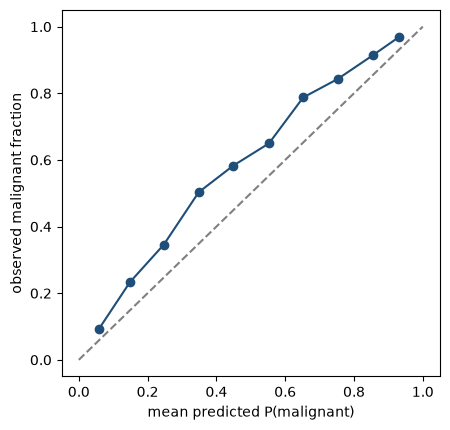

Brier score: 0.1442


,n,mean_pred,frac_malignant
bin,,,
0,453,0.058478,0.092715
1,514,0.148835,0.233463
2,405,0.246955,0.345679
3,316,0.348592,0.503165
4,307,0.449277,0.583062
5,374,0.552898,0.649733
6,433,0.652256,0.787529
7,598,0.752479,0.842809
8,1035,0.854601,0.914010


In [10]:
bins = np.linspace(0, 1, 11)
idx = np.clip(np.digitize(p, bins) - 1, 0, 9)
cal = pd.DataFrame({"bin": idx, "p": p, "y": y}).groupby("bin").agg(n=("y", "size"), mean_pred=("p", "mean"),
                                                                    frac_malignant=("y", "mean"))
fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.plot([0, 1], [0, 1], "--", color="grey")
ax.plot(cal.mean_pred, cal.frac_malignant, "o-", color="#1f4e79")
ax.set_xlabel("mean predicted P(malignant)")
ax.set_ylabel("observed malignant fraction")
savefig("fig_calibration")
print(f"Brier score: {np.mean((p - y) ** 2):.4f}")
cal

The Brier score is 0.144. The reliability curve shows how far the probabilities deviate from observed frequencies;
any downstream use of them as probabilities would need recalibration.

## 10. What does the ≥80%-sensitivity operating point look like?
This is the same cut that defines the hard positives in notebook 02.

In [11]:
thr = tail_threshold(y, p)
op = {"threshold": thr, "sensitivity": float((p[y == 1] >= thr).mean()), "specificity": float((p[y == 0] < thr).mean())}
print(op)
pd.Series(t["y_cls"][(y == 0) & (p >= thr)]).value_counts().rename("benign lesions above the cut")

{'threshold': 0.5258751213550568, 'sensitivity': 0.8002316155182397, 'specificity': 0.7788353863381859}


BKL        202
AKIEC      111
NV          54
INF         10
BEN_OTH      7
DF           7
VASC         4
Name: benign lesions above the cut, dtype: int64

At sensitivity 0.800 the specificity is 0.779. Most benign lesions above the cut are BKL (202), AKIEC (111) and NV (54):
the same mimics that outrank the hard positives.

## 11. Test-set predictions
The 479 official test lesions have no public labels, so there is no test score; we only check that the score
distributions look sane.

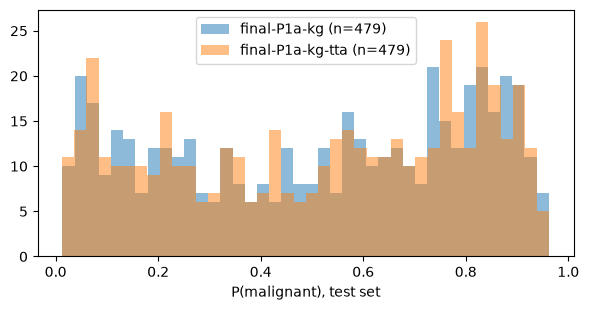

In [12]:
pred = {"final-P1a-kg": pd.read_csv(inp("pred_final")), "final-P1a-kg-tta": pd.read_csv(inp("pred_tta"))}
fig, ax = plt.subplots(figsize=(6, 3.2))
for name, df in pred.items():
    ax.hist(df.target_binary, bins=40, alpha=0.5, label=f"{name} (n={len(df)})")
ax.set_xlabel("P(malignant), test set")
ax.legend()
savefig("fig_test_scores")

## 12. Save the metrics

In [13]:
def jsonable(x):
    if isinstance(x, dict):
        return {str(k): jsonable(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [jsonable(v) for v in x]
    return float(x) if isinstance(x, (np.floating, np.integer)) else x


metrics = {"model": "final-P1a-kg", "oof_components": {k: final[k] for k in COMPONENTS},
           "pauc80_by_code_group": {CODE_GROUPS[g]: v for g, v in final["pauc80_by_group"].items()},
           "fold_scores": final["fold_scores"], "tta": tta, "seed_ensembling": ensembling,
           "operating_point_tpr80": op, "bootstrap": {"n_boot": N_BOOT, "seed": BOOT_SEED}}
out("metrics_json").write_text(json.dumps(jsonable(metrics), indent=1) + "\n")
print("saved", OUTPUTS["metrics_json"])

saved results/metrics/final_metrics.json


## Takeaways
- Pooled OOF score 0.6505: pAUC80 0.5716, macro-AUC 0.8911, FairGap 0.1693. pAUC80 is the bottleneck.
- FairGap is driven by the small code 1–2 group scoring highest, not by a poorly served large group.
- Seed averaging helps (+0.021). TTA adds a further +0.005 that we cannot distinguish from noise. The clinical image is worth about 0.011.
- BKL, AKIEC and NV are the benign lesions that crowd the high-sensitivity region.

Next, notebook 06 puts these numbers next to every experiment we ran.